## Bagian 1: Inisialisasi dan Memuat Data Bersih

Muat dataset hasil pembersihan dari folder `data/processed/` menggunakan Polars.

**Catatan karakteristik dataset:** Dataset Cosmopedia Indonesia memiliki kolom waktu `created_at`, tetapi tidak memiliki kolom koordinat geografis atau wilayah. Oleh karena itu, analisis spasial berbasis lokasi tidak dapat dilakukan. Analisis keenam disesuaikan menjadi analisis hubungan multi-dimensi berdasarkan variabel yang tersedia.

In [1]:
from pathlib import Path
import duckdb
import polars as pl
import plotly.express as px
import plotly.graph_objects as go
import pandas as pd

# Lokasi folder utama proyek
PROJECT_ROOT = Path.cwd().resolve().parent

# Lokasi dataset hasil Milestone 2
DATA_PATH = PROJECT_ROOT / "data" / "processed" / "cosmopedia_id_clean.parquet"

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Data bersih tidak ditemukan: {DATA_PATH}. "
        "Pastikan Milestone 2 sudah dijalankan."
    )

# Membaca dataset bersih
df = pl.read_parquet(DATA_PATH)

print(f"Data berhasil dimuat: {df.shape[0]:,} baris x {df.shape[1]} kolom")
print("\nDaftar kolom:")
print(df.columns)

display(df.head())

Data berhasil dimuat: 120,068 baris x 9 kolom

Daftar kolom:
['id', 'prompt', 'text', 'token_length', 'audience', 'format', 'seed_data', 'datasheet_global_id', 'created_at']


id,prompt,text,token_length,audience,format,seed_data,datasheet_global_id,created_at
i64,str,str,i64,str,str,str,i64,str
1,"""Berikut adalah ekstrak dari ha…","""Dahulu kala, ada sebuah agen y…",699,"""children""","""story""","""fineweb""",1,"""2026-02-18 07:35:54"""
24,"""Berikut kutipan dari sebuah ha…","""Suatu ketika, di sebuah negeri…",137,"""children""","""story""","""fineweb""",2,"""2026-02-18 08:19:23"""
25,"""Berikut kutipan dari sebuah ha…","""Di kota Popville, hiduplah ban…",93,"""children""","""story""","""fineweb""",3,"""2026-02-18 08:19:23"""
26,"""Berikut kutipan tentang chipmu…","""Di sebuah lingkungan yang tena…",76,"""children""","""story""","""fineweb""",4,"""2026-02-18 08:19:23"""
27,"""Berikut kutipan tentang terapi…","""Timmy pernah merasa sangat sed…",88,"""children""","""story""","""fineweb""",5,"""2026-02-18 08:19:23"""


## Bagian 2: Analisis Temporal dan Window Functions (Materi Pertemuan 6)

Kolom `created_at` digunakan untuk melihat distribusi waktu pembuatan data. Analisis dilakukan dengan mengelompokkan data per jam menggunakan `group_by_dynamic()`, kemudian menghitung moving average tiga interval.

In [2]:
# Mengubah created_at menjadi tipe Datetime
df_temporal_base = (
    df.with_columns(
        pl.col("created_at")
        .cast(pl.String)
        .str.to_datetime(
            format="%Y-%m-%d %H:%M:%S",
            strict=False
        )
        .alias("created_at_dt")
    )
    .filter(pl.col("created_at_dt").is_not_null())
)

if df_temporal_base.height == 0:
    raise ValueError(
        "Kolom created_at tidak berhasil dikonversi menjadi Datetime. "
        "Periksa format tanggal pada dataset."
    )

# Agregasi jumlah dokumen per jam dan moving average 3 interval
df_temporal = (
    df_temporal_base
    .sort("created_at_dt")
    .group_by_dynamic(
        "created_at_dt",
        every="1h"
    )
    .agg(
        pl.len().alias("jumlah_dokumen")
    )
    .sort("created_at_dt")
    .with_columns(
        pl.col("jumlah_dokumen")
        .rolling_mean(window_size=3)
        .alias("moving_average_3_jam")
    )
)

print("Rentang waktu dataset:")
display(
    df_temporal_base.select([
        pl.col("created_at_dt").min().alias("waktu_awal"),
        pl.col("created_at_dt").max().alias("waktu_akhir")
    ])
)

print("Agregasi jumlah dokumen per jam:")
display(df_temporal)

print(
    f"Jumlah baris dengan waktu valid: "
    f"{df_temporal_base.height:,}"
)
print(
    f"Jumlah interval waktu: "
    f"{df_temporal.height:,}"
)

Rentang waktu dataset:


waktu_awal,waktu_akhir
datetime[μs],datetime[μs]
2026-02-18 07:35:54,2026-03-06 03:44:48


Agregasi jumlah dokumen per jam:


created_at_dt,jumlah_dokumen,moving_average_3_jam
datetime[μs],u32,f64
2026-02-18 07:00:00,1,null
2026-02-18 08:00:00,70,null
2026-02-18 09:00:00,1,24.0
2026-02-18 10:00:00,49,40.0
2026-02-19 03:00:00,94,48.0
…,…,…
2026-03-03 08:00:00,1456,1192.333333
2026-03-03 09:00:00,1563,1270.333333
2026-03-03 10:00:00,791,1270.0


Jumlah baris dengan waktu valid: 120,068
Jumlah interval waktu: 134


## Bagian 3: Minimal 6 Visualisasi Interaktif (Plotly / Altair)

Enam visualisasi berikut disesuaikan dengan kolom yang tersedia pada dataset, yaitu tren waktu, distribusi token, korelasi numerik, komposisi kategori, pola waktu berdasarkan kelompok audience, dan hubungan multi-dimensi. Dataset tidak memiliki atribut lokasi sehingga visualisasi spasial tidak digunakan.

In [3]:
# Menambahkan panjang teks dan prompt dalam satuan karakter
df_plot = df.with_columns([
    pl.col("text").str.len_chars().alias("text_length"),
    pl.col("prompt").str.len_chars().alias("prompt_length")
])

# Mengubah Polars DataFrame menjadi Pandas untuk Plotly
pdf = df_plot.to_pandas()

# Konversi kolom waktu
pdf["created_at"] = pd.to_datetime(
    pdf["created_at"],
    format="%Y-%m-%d %H:%M:%S",
    errors="coerce"
)

# Mengambil informasi jam
pdf["hour"] = pdf["created_at"].dt.hour

print("Data untuk visualisasi berhasil disiapkan.")
print(f"Jumlah baris: {len(pdf):,}")
display(pdf.head())

Data untuk visualisasi berhasil disiapkan.
Jumlah baris: 120,068


,id,prompt,text,token_length,audience,format,seed_data,datasheet_global_id,created_at,text_length,prompt_length,hour
0,1,"Berikut adalah ekstrak dari halaman web: ""Home...","Dahulu kala, ada sebuah agen yang ramah bernam...",699,children,story,fineweb,1,2026-02-18 07:35:54,3409,1333,7
1,24,"Berikut kutipan dari sebuah halaman web: ""Heal...","Suatu ketika, di sebuah negeri ajaib bernama B...",137,children,story,fineweb,2,2026-02-18 08:19:23,674,248,8
2,25,Berikut kutipan dari sebuah halaman web mengen...,"Di kota Popville, hiduplah banyak orang dan he...",93,children,story,fineweb,3,2026-02-18 08:19:23,522,261,8
3,26,Berikut kutipan tentang chipmunk (tupai tanah ...,"Di sebuah lingkungan yang tenang, hidup chipmu...",76,children,story,fineweb,4,2026-02-18 08:19:23,398,141,8
4,27,Berikut kutipan tentang terapi dan cara mengat...,Timmy pernah merasa sangat sedih setelah terja...,88,children,story,fineweb,5,2026-02-18 08:19:23,401,182,8


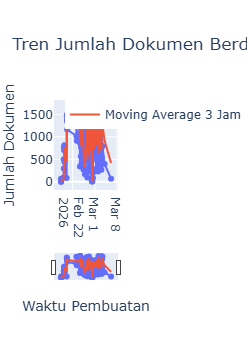

In [4]:
# Visualisasi 1: Tren jumlah dokumen per jam
temporal_pdf = df_temporal.to_pandas()

fig1 = px.line(
    temporal_pdf,
    x="created_at_dt",
    y="jumlah_dokumen",
    markers=True,
    title="Tren Jumlah Dokumen Berdasarkan Waktu Pembuatan",
    labels={
        "created_at_dt": "Waktu Pembuatan",
        "jumlah_dokumen": "Jumlah Dokumen"
    }
)

fig1.add_scatter(
    x=temporal_pdf["created_at_dt"],
    y=temporal_pdf["moving_average_3_jam"],
    mode="lines",
    name="Moving Average 3 Jam"
)

fig1.update_xaxes(rangeslider_visible=True)
fig1.update_layout(hovermode="x unified")
fig1.show()

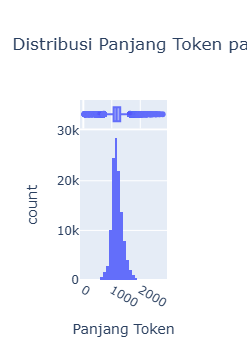

In [5]:
# Visualisasi 2: Distribusi dan outlier token_length
fig2 = px.histogram(
    pdf,
    x="token_length",
    marginal="box",
    nbins=50,
    title="Distribusi Panjang Token pada Dataset",
    labels={
        "token_length": "Panjang Token"
    }
)

fig2.show()

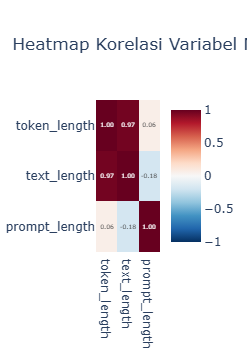

Matriks korelasi:


,token_length,text_length,prompt_length
token_length,1.000000,0.967891,0.060782
text_length,0.967891,1.000000,-0.184374
prompt_length,0.060782,-0.184374,1.000000


In [6]:
# Visualisasi 3: Korelasi antarvariabel numerik
kolom_korelasi = [
    "token_length",
    "text_length",
    "prompt_length"
]

correlation = pdf[kolom_korelasi].corr(numeric_only=True)

fig3 = px.imshow(
    correlation,
    text_auto=".2f",
    aspect="auto",
    color_continuous_scale="RdBu_r",
    zmin=-1,
    zmax=1,
    title="Heatmap Korelasi Variabel Numerik"
)

fig3.show()

print("Matriks korelasi:")
display(correlation)

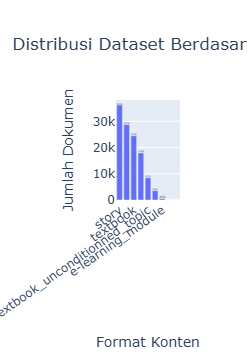

,format,jumlah
0,story,36230
1,dialogue,28758
2,textbook,24508
3,story_children,17989
4,textbook_unconditionned_topic,8521
5,textbook_narrative,3562
6,e-learning_module,498
7,Dialogue,1
8,,1


In [7]:
# Visualisasi 4: Komposisi dataset berdasarkan format
format_counts = (
    df.group_by("format")
    .agg(pl.len().alias("jumlah"))
    .sort("jumlah", descending=True)
    .with_columns(
        pl.col("format")
        .fill_null("Tidak diketahui")
    )
    .to_pandas()
)

fig4 = px.bar(
    format_counts,
    x="format",
    y="jumlah",
    title="Distribusi Dataset Berdasarkan Format",
    labels={
        "format": "Format Konten",
        "jumlah": "Jumlah Dokumen"
    },
    text="jumlah"
)

fig4.update_layout(xaxis_tickangle=-35)
fig4.show()

display(format_counts)

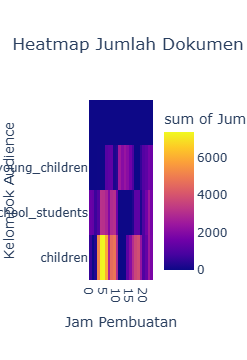

In [8]:
# Visualisasi 5: Pola waktu berdasarkan jam dan audience
hourly_data = pdf.dropna(
    subset=["hour"]
).copy()

hourly_data["audience"] = (
    hourly_data["audience"]
    .fillna("Tidak diketahui")
)

hourly_audience = (
    hourly_data
    .groupby(["hour", "audience"])
    .size()
    .reset_index(name="jumlah")
)

fig5 = px.density_heatmap(
    hourly_audience,
    x="hour",
    y="audience",
    z="jumlah",
    histfunc="sum",
    nbinsx=24,
    title="Heatmap Jumlah Dokumen Berdasarkan Jam dan Audience",
    labels={
        "hour": "Jam Pembuatan",
        "audience": "Kelompok Audience",
        "jumlah": "Jumlah Dokumen"
    }
)

fig5.show()

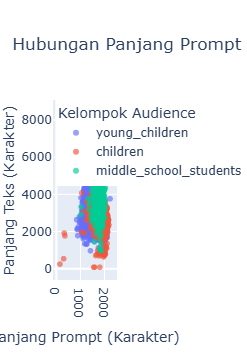

In [9]:
# Visualisasi 6: Hubungan panjang prompt dan teks berdasarkan audience
# Sampling maksimal 5.000 baris agar visualisasi tetap responsif

scatter_pdf = pdf.sample(
    n=min(5000, len(pdf)),
    random_state=42
).copy()

scatter_pdf["audience"] = (
    scatter_pdf["audience"]
    .fillna("Tidak diketahui")
)

fig6 = px.scatter(
    scatter_pdf,
    x="prompt_length",
    y="text_length",
    color="audience",
    hover_data=[
        "format",
        "token_length"
    ],
    title="Hubungan Panjang Prompt dan Teks Berdasarkan Audience",
    labels={
        "prompt_length": "Panjang Prompt (Karakter)",
        "text_length": "Panjang Teks (Karakter)",
        "audience": "Kelompok Audience"
    },
    opacity=0.65
)

fig6.show()

## Bagian 4: Rumusan 5 Insight Analitik Utama

### 1. Pola Distribusi Dokumen Berdasarkan Waktu
Berdasarkan visualisasi tren waktu, jumlah dokumen mengalami fluktuasi selama periode 18 Februari hingga 6 Maret 2026. Perubahan jumlah dokumen terlihat cukup bervariasi pada setiap interval waktu, sehingga distribusi data tidak menunjukkan pola peningkatan yang konsisten. Sementara itu, heatmap menunjukkan bahwa jumlah dokumen pada setiap jam berbeda untuk masing-masing kelompok audience. Kategori `children` memiliki intensitas tertinggi pada beberapa jam pagi, terutama sekitar pukul 4–6.

### 2. Distribusi Data Berdasarkan Audience
Hasil analisis menunjukkan bahwa dataset didominasi oleh kategori `children` sebanyak 64.989 data (54,13%). Selanjutnya, kategori `middle_school_students` berjumlah 33.078 data dan `young_children` sebanyak 22.000 data. Dominasi kategori children menunjukkan bahwa sebagian besar konten dalam dataset ditujukan kepada kelompok anak-anak. Distribusi ini menjadi karakteristik penting dalam memahami sasaran pengguna konten.

### 3. Komposisi Format Konten
Berdasarkan visualisasi komposisi kategori, format `story` merupakan format yang paling banyak ditemukan, yaitu 36.230 data (30,18%). Posisi berikutnya ditempati oleh `dialogue` sebanyak 28.758 data dan `textbook` sebanyak 24.508 data. Hal ini menunjukkan bahwa dataset memiliki variasi penyajian konten, dengan format cerita sebagai kategori dominan. Perbedaan jumlah antarformat juga memperlihatkan bahwa distribusi jenis konten belum merata.

### 4. Distribusi Panjang Teks dan Outlier
Variabel `token_length` memiliki rata-rata sebesar 1.187,94 token dan median 1.168 token, dengan nilai minimum 36 dan maksimum 2.787 token. Berdasarkan metode Interquartile Range (IQR), ditemukan 3.790 data outlier atau sekitar 3,16%, dengan batas bawah 718,5 dan batas atas 1.642,5. Data outlier tetap dipertahankan karena perbedaan panjang teks dapat mencerminkan variasi konten yang valid, bukan selalu kesalahan data.

### 5. Hubungan Panjang Karakter Teks dengan Jumlah Token
Hasil analisis korelasi Pearson menunjukkan nilai sebesar 0,9679 antara `text_length` dan `token_length`. Nilai tersebut menunjukkan hubungan linear positif yang sangat kuat, yaitu semakin panjang teks berdasarkan jumlah karakter, cenderung semakin besar pula jumlah tokennya. Temuan ini memperlihatkan bahwa panjang karakter dapat menjadi indikator yang berkaitan erat dengan jumlah token dalam dataset.

### Kesimpulan
Secara keseluruhan, hasil eksplorasi menunjukkan bahwa dataset Cosmopedia Indonesia memiliki karakteristik yang beragam dari sisi waktu pembuatan, kelompok audience, format konten, dan panjang teks. Kategori `children` serta format `story` menjadi kelompok yang paling dominan. Selain itu, hubungan yang sangat kuat antara panjang karakter dan jumlah token menunjukkan adanya keterkaitan antara ukuran teks dengan representasi tokennya.

## Hasil dan Insight Analisis

Berdasarkan proses Exploratory Data Analysis (EDA) terhadap 120.068 data Cosmopedia Indonesia, diperoleh beberapa insight sebagai berikut.

### 1. Distribusi Audience Didominasi oleh Children

Kategori audience `children` memiliki jumlah data terbanyak, yaitu 64.989 data atau sekitar 54,13% dari keseluruhan dataset. Selanjutnya, kategori `middle_school_students` sebanyak 33.078 data dan `young_children` sebanyak 22.000 data. Hal ini menunjukkan bahwa dataset lebih banyak berisi teks yang ditujukan untuk pembaca anak-anak.

### 2. Format Story Menjadi Format yang Paling Dominan

Format `story` memiliki jumlah data tertinggi sebanyak 36.230 data atau sekitar 30,18%. Berikutnya adalah `dialogue` sebanyak 28.758 data dan `textbook` sebanyak 24.508 data. Temuan ini menunjukkan bahwa format naratif merupakan salah satu bentuk penyajian teks yang paling banyak ditemukan dalam dataset.

### 3. Panjang Token Memiliki Distribusi yang Relatif Terpusat

Berdasarkan analisis statistik, panjang token memiliki nilai rata-rata sekitar 1.187,94 token dan median 1.168 token. Nilai minimum adalah 36 token, sedangkan nilai maksimum mencapai 2.787 token. Kedekatan nilai rata-rata dan median menunjukkan bahwa pusat distribusi panjang token berada pada kisaran yang relatif berdekatan.

### 4. Panjang Karakter Teks Memiliki Hubungan Positif yang Sangat Kuat dengan Jumlah Token

Hasil perhitungan korelasi Pearson antara panjang karakter teks dan jumlah token menghasilkan nilai sebesar 0,9679. Nilai tersebut menunjukkan hubungan linear positif yang sangat kuat. Artinya, teks dengan jumlah karakter lebih banyak cenderung memiliki jumlah token lebih tinggi.

### 5. Terdapat Sejumlah Data dengan Panjang Token Ekstrem

Deteksi outlier menggunakan metode Interquartile Range (IQR) menemukan 3.790 data atau sekitar 3,16% dari keseluruhan dataset. Data tersebut berada di luar batas bawah 718,5 token dan batas atas 1.642,5 token. Data tetap dipertahankan karena panjang teks yang ekstrem tidak selalu menunjukkan kesalahan data dan dapat merepresentasikan variasi alami dalam dataset.

### Kesimpulan EDA

Secara keseluruhan, dataset Cosmopedia Indonesia memiliki variasi audience, format, dan panjang teks yang cukup beragam. Distribusi audience didominasi oleh kategori anak-anak, sedangkan format story menjadi kategori yang paling banyak ditemukan. Hubungan yang sangat kuat antara panjang karakter dan jumlah token juga menunjukkan konsistensi pola ukuran teks. Hasil analisis ini dapat menjadi dasar untuk memahami karakteristik dataset sebelum digunakan dalam pengolahan data lebih lanjut.